# Fleet vs Public User Behaviour Analysis

Compare commercial and public EV charging behaviour, energy consumption, and revenue contribution.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)

## 1. Data Loading and Initial Inspection

Load the EV charging sessions dataset and inspect its structure, data types, and user categories.


In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the sessions data
DATA_PATH = Path("../../data/raw/ev_charging_dataset.xlsx")

sessions = pd.read_excel(
    DATA_PATH,
    sheet_name="sessions"
)

print("Dataset shape:", sessions.shape)

display(sessions.head())
display(sessions.info())

Dataset shape: (294024, 15)


,session_id,station_id,charger_id,charger_type,start_timestamp,end_timestamp,session_duration_minutes,energy_kwh,price_per_kwh,total_cost,payment_method,user_type,customer_id,station_region,year
0,S_00000001,STN_001,STN_001_CH_02,DC_150kW,2022-01-01 08:30:00,2022-01-01 08:56:00,26,56.90,0.47,26.74,app,fleet,CUST_00134,North West,2022
1,S_00000002,STN_001,STN_001_CH_02,DC_150kW,2022-01-01 09:20:00,2022-01-01 09:41:00,21,40.70,0.46,18.72,app,delivery,CUST_00195,North West,2022
2,S_00000003,STN_001,STN_001_CH_04,DC_50kW,2022-01-01 09:00:00,2022-01-01 09:48:00,48,30.90,0.47,14.52,rfid,public,CUST_01935,North West,2022
3,S_00000004,STN_001,STN_001_CH_01,DC_50kW,2022-01-01 23:20:00,2022-01-02 00:01:00,41,28.40,0.45,12.78,rfid,public,CUST_00036,North West,2022
4,S_00000005,STN_001,STN_001_CH_01,DC_50kW,2022-01-01 16:10:00,2022-01-01 17:00:00,50,31.70,0.56,17.75,rfid,taxi,CUST_00011,North West,2022


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 294024 entries, 0 to 294023
Data columns (total 15 columns):
 #   Column                    Non-Null Count   Dtype         
---  ------                    --------------   -----         
 0   session_id                294024 non-null  object        
 1   station_id                294024 non-null  object        
 2   charger_id                294024 non-null  object        
 3   charger_type              294024 non-null  object        
 4   start_timestamp           294024 non-null  datetime64[ns]
 5   end_timestamp             294024 non-null  datetime64[ns]
 6   session_duration_minutes  294024 non-null  int64         
 7   energy_kwh                294024 non-null  float64       
 8   price_per_kwh             294024 non-null  float64       
 9   total_cost                294024 non-null  float64       
 10  payment_method            294024 non-null  object        
 11  user_type                 294024 non-null  object        
 12  cu

None

In [4]:
sessions["user_type"].value_counts().to_frame("total_sessions")

,total_sessions
user_type,
public,73754
fleet,73696
delivery,73339
taxi,73235


In [7]:
user_distribution = sessions["user_type"].value_counts().reset_index()
user_distribution.columns = ["user_type", "total_sessions"]

user_distribution["percentage"] = (
    user_distribution["total_sessions"] / len(sessions) * 100
)

user_distribution

,user_type,total_sessions,percentage
0,public,73754,25.08
1,fleet,73696,25.06
2,delivery,73339,24.94
3,taxi,73235,24.91


In [8]:
sessions["customer_segment"] = np.where(
    sessions["user_type"] == "public",
    "Public",
    "Commercial"
)

sessions["customer_segment"].value_counts()

customer_segment
Commercial    220270
Public         73754
Name: count, dtype: int64

In [9]:
segment_distribution = sessions["customer_segment"].value_counts().reset_index()
segment_distribution.columns = ["customer_segment", "total_sessions"]

segment_distribution["percentage"] = (
    segment_distribution["total_sessions"] / len(sessions) * 100
)

segment_distribution

,customer_segment,total_sessions,percentage
0,Commercial,220270,74.92
1,Public,73754,25.08


In [10]:
customer_counts = (
    sessions.groupby("customer_segment")["customer_id"]
    .nunique()
    .reset_index(name="unique_customers")
)

customer_counts

,customer_segment,unique_customers
0,Commercial,7510
1,Public,6452


In [12]:
session_frequency = (
    sessions.groupby("customer_segment")
    .agg(
        total_sessions=("session_id", "count"),
        unique_customers=("customer_id", "nunique")
    )
    .reset_index()
)

session_frequency["sessions_per_customer"] = (
    session_frequency["total_sessions"] /
    session_frequency["unique_customers"]
)

session_frequency

,customer_segment,total_sessions,unique_customers,sessions_per_customer
0,Commercial,220270,7510,29.33
1,Public,73754,6452,11.43


In [13]:
energy_comparison = (
    sessions.groupby("customer_segment")
    .agg(
        total_energy_kwh=("energy_kwh", "sum"),
        average_energy_per_session=("energy_kwh", "mean"),
        unique_customers=("customer_id", "nunique")
    )
    .reset_index()
)

energy_comparison["energy_per_customer"] = (
    energy_comparison["total_energy_kwh"] /
    energy_comparison["unique_customers"]
)

energy_comparison

,customer_segment,total_energy_kwh,average_energy_per_session,unique_customers,energy_per_customer
0,Commercial,"10,344,901.20",46.96,7510,"1,377.48"
1,Public,"3,463,844.60",46.96,6452,536.86


In [14]:
revenue_comparison = (
    sessions.groupby("customer_segment")
    .agg(
        total_revenue=("total_cost", "sum"),
        average_revenue_per_session=("total_cost", "mean"),
        unique_customers=("customer_id", "nunique")
    )
    .reset_index()
)

revenue_comparison["revenue_per_customer"] = (
    revenue_comparison["total_revenue"] /
    revenue_comparison["unique_customers"]
)

revenue_comparison["revenue_share"] = (
    revenue_comparison["total_revenue"] /
    revenue_comparison["total_revenue"].sum() * 100
)

revenue_comparison

,customer_segment,total_revenue,average_revenue_per_session,unique_customers,revenue_per_customer,revenue_share
0,Commercial,"6,120,481.87",27.79,7510,814.98,74.90
1,Public,"2,050,618.25",27.80,6452,317.83,25.10


In [15]:
duration_comparison = (
    sessions.groupby("customer_segment")
    .agg(
        total_duration_minutes=("session_duration_minutes", "sum"),
        average_duration_minutes=("session_duration_minutes", "mean"),
        unique_customers=("customer_id", "nunique")
    )
    .reset_index()
)

duration_comparison["duration_per_customer"] = (
    duration_comparison["total_duration_minutes"] /
    duration_comparison["unique_customers"]
)

duration_comparison

,customer_segment,total_duration_minutes,average_duration_minutes,unique_customers,duration_per_customer
0,Commercial,7731212,35.10,7510,"1,029.46"
1,Public,2587490,35.08,6452,401.04


In [16]:
regional_comparison = (
    sessions.groupby(["station_region", "customer_segment"])
    .agg(
        total_sessions=("session_id", "count"),
        total_energy_kwh=("energy_kwh", "sum"),
        total_revenue=("total_cost", "sum")
    )
    .reset_index()
)

regional_comparison

,station_region,customer_segment,total_sessions,total_energy_kwh,total_revenue
0,London,Commercial,30532,"1,479,311.60","873,170.74"
1,London,Public,10228,"498,779.00","294,721.83"
2,Midlands,Commercial,37770,"1,925,304.20","1,130,467.05"
3,Midlands,Public,12828,"651,405.60","382,421.67"
4,North East,Commercial,22960,"1,056,188.10","625,134.37"
5,North East,Public,7479,"341,862.20","202,704.99"
6,North West,Commercial,49040,"2,238,337.20","1,303,448.14"
7,North West,Public,16749,"766,797.90","446,211.65"
8,Scotland,Commercial,15163,"709,749.10","426,381.48"
9,Scotland,Public,5079,"237,261.40","142,589.85"


In [17]:
regional_sessions = regional_comparison.pivot(
    index="station_region",
    columns="customer_segment",
    values="total_sessions"
)

regional_sessions

customer_segment,Commercial,Public
station_region,,
London,30532,10228
Midlands,37770,12828
North East,22960,7479
North West,49040,16749
Scotland,15163,5079
South East,18952,6216
South West,22936,7465
Wales,7662,2497
Yorkshire & Humber,15255,5213


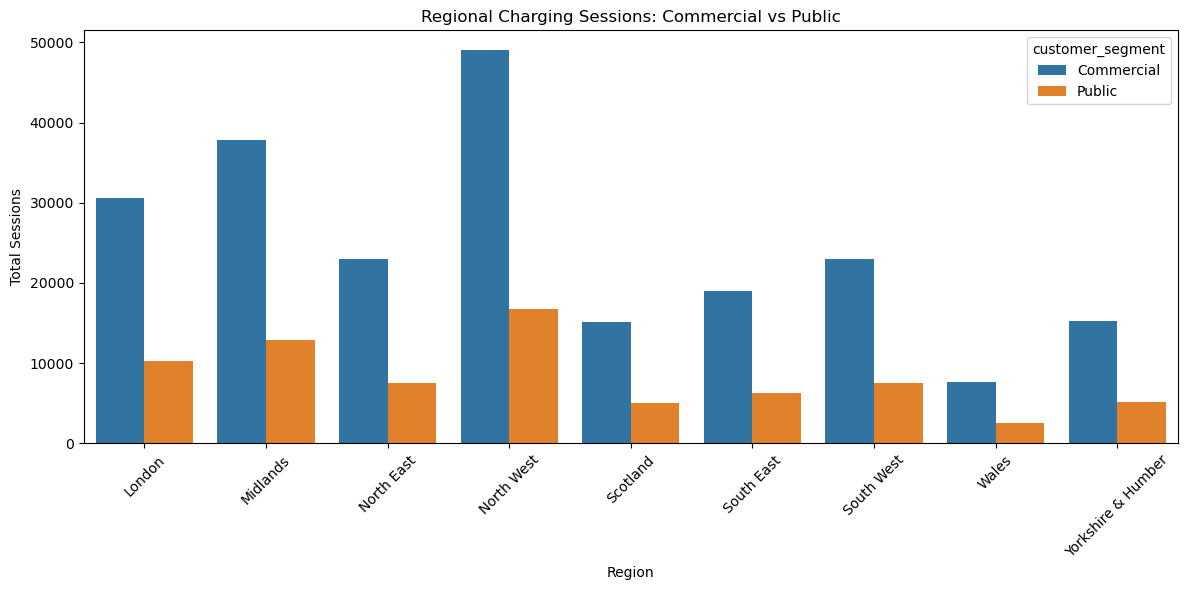

In [18]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=regional_comparison,
    x="station_region",
    y="total_sessions",
    hue="customer_segment"
)

plt.title("Regional Charging Sessions: Commercial vs Public")
plt.xlabel("Region")
plt.ylabel("Total Sessions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [19]:
charger_comparison = (
    sessions.groupby(["charger_type", "customer_segment"])
    .agg(
        total_sessions=("session_id", "count"),
        total_energy_kwh=("energy_kwh", "sum"),
        total_revenue=("total_cost", "sum")
    )
    .reset_index()
)

charger_comparison

,charger_type,customer_segment,total_sessions,total_energy_kwh,total_revenue
0,DC_150kW,Commercial,72623,"3,556,276.50","2,102,762.91"
1,DC_150kW,Public,24354,"1,192,197.30","704,319.61"
2,DC_300kW,Commercial,45112,"3,407,552.40","2,009,182.95"
3,DC_300kW,Public,15114,"1,141,673.80","674,486.08"
4,DC_50kW,Commercial,102535,"3,381,072.30","2,008,536.01"
5,DC_50kW,Public,34286,"1,129,973.50","671,812.56"


In [20]:
charger_comparison["segment_share"] = (
    charger_comparison["total_sessions"] /
    charger_comparison.groupby("customer_segment")["total_sessions"].transform("sum") * 100
)

charger_comparison

,charger_type,customer_segment,total_sessions,total_energy_kwh,total_revenue,segment_share
0,DC_150kW,Commercial,72623,"3,556,276.50","2,102,762.91",32.97
1,DC_150kW,Public,24354,"1,192,197.30","704,319.61",33.02
2,DC_300kW,Commercial,45112,"3,407,552.40","2,009,182.95",20.48
3,DC_300kW,Public,15114,"1,141,673.80","674,486.08",20.49
4,DC_50kW,Commercial,102535,"3,381,072.30","2,008,536.01",46.55
5,DC_50kW,Public,34286,"1,129,973.50","671,812.56",46.49


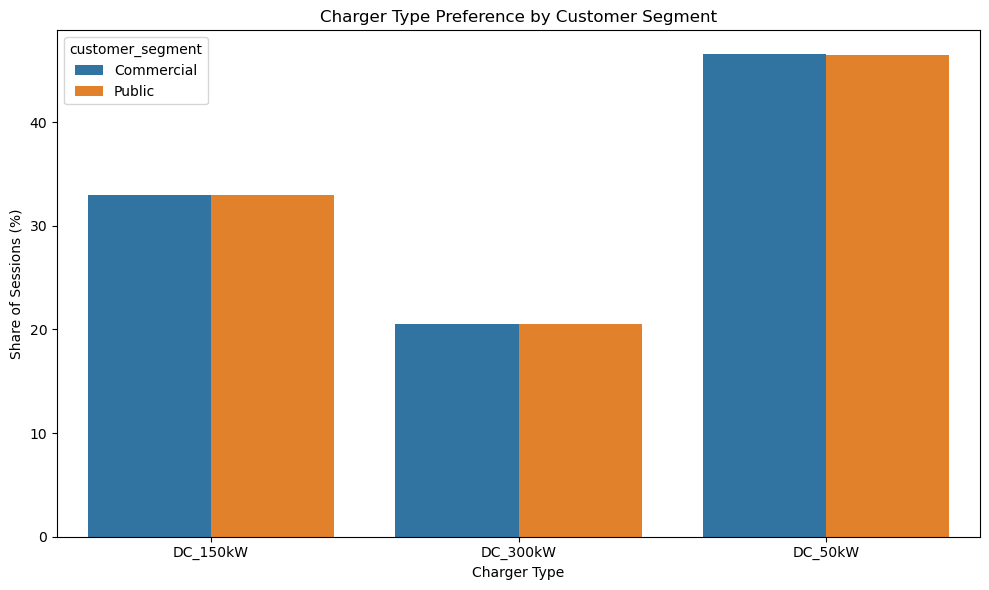

In [21]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=charger_comparison,
    x="charger_type",
    y="segment_share",
    hue="customer_segment"
)

plt.title("Charger Type Preference by Customer Segment")
plt.xlabel("Charger Type")
plt.ylabel("Share of Sessions (%)")
plt.tight_layout()
plt.show()

In [22]:
payment_comparison = (
    sessions.groupby(["payment_method", "customer_segment"])
    .size()
    .reset_index(name="total_sessions")
)

payment_comparison["segment_share"] = (
    payment_comparison["total_sessions"] /
    payment_comparison.groupby("customer_segment")["total_sessions"].transform("sum") * 100
)

payment_comparison

,payment_method,customer_segment,total_sessions,segment_share
0,app,Commercial,73785,33.50
1,app,Public,24482,33.19
2,card,Commercial,73310,33.28
3,card,Public,24553,33.29
4,rfid,Commercial,73175,33.22
5,rfid,Public,24719,33.52


In [23]:
sessions["month"] = sessions["start_timestamp"].dt.to_period("M")

monthly_comparison = (
    sessions.groupby(["month", "customer_segment"])
    .agg(
        total_sessions=("session_id", "count"),
        total_energy_kwh=("energy_kwh", "sum"),
        total_revenue=("total_cost", "sum")
    )
    .reset_index()
)

monthly_comparison["month"] = monthly_comparison["month"].astype(str)

monthly_comparison.head()


,month,customer_segment,total_sessions,total_energy_kwh,total_revenue
0,2022-01,Commercial,2502,"123,259.20","62,958.72"
1,2022-01,Public,892,"43,907.10","22,461.46"
2,2022-02,Commercial,2359,"118,301.80","60,423.78"
3,2022-02,Public,761,"37,407.10","19,065.87"
4,2022-03,Commercial,2616,"130,191.60","66,584.91"


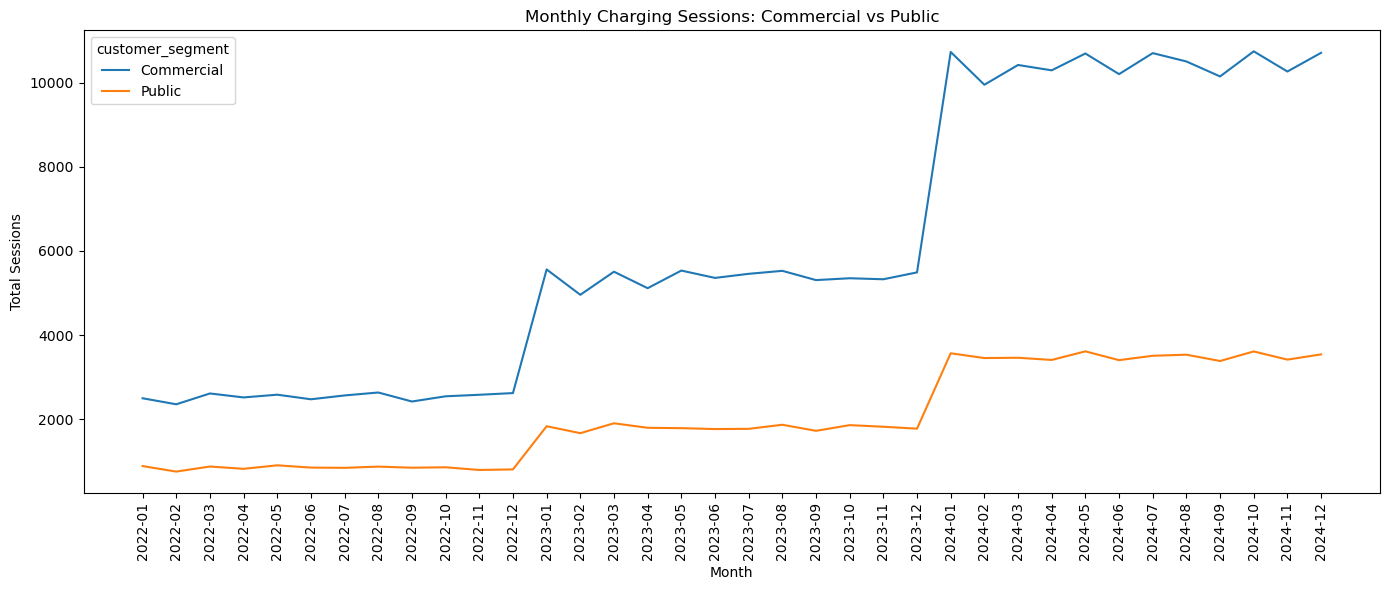

In [24]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_comparison,
    x="month",
    y="total_sessions",
    hue="customer_segment"
)

plt.title("Monthly Charging Sessions: Commercial vs Public")
plt.xlabel("Month")
plt.ylabel("Total Sessions")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [25]:
sessions["year"] = sessions["start_timestamp"].dt.year

annual_comparison = (
    sessions.groupby(["year", "customer_segment"])
    .agg(
        total_sessions=("session_id", "count"),
        total_energy_kwh=("energy_kwh", "sum"),
        total_revenue=("total_cost", "sum")
    )
    .reset_index()
)

annual_comparison

,year,customer_segment,total_sessions,total_energy_kwh,total_revenue
0,2022,Commercial,30456,"1,509,749.10","771,888.32"
1,2022,Public,10184,"502,078.90","256,883.48"
2,2023,Commercial,64501,"3,031,569.80","1,937,340.80"
3,2023,Public,21631,"1,017,554.70","650,433.12"
4,2024,Commercial,125313,"5,803,582.30","3,411,252.75"
5,2024,Public,41939,"1,944,211.00","1,143,301.65"


In [26]:
annual_comparison["session_growth_pct"] = (
    annual_comparison.groupby("customer_segment")["total_sessions"]
    .pct_change() * 100
)

annual_comparison

,year,customer_segment,total_sessions,total_energy_kwh,total_revenue,session_growth_pct
0,2022,Commercial,30456,"1,509,749.10","771,888.32",NaN
1,2022,Public,10184,"502,078.90","256,883.48",NaN
2,2023,Commercial,64501,"3,031,569.80","1,937,340.80",111.78
3,2023,Public,21631,"1,017,554.70","650,433.12",112.40
4,2024,Commercial,125313,"5,803,582.30","3,411,252.75",94.28
5,2024,Public,41939,"1,944,211.00","1,143,301.65",93.88


In [27]:
annual_comparison["revenue_per_session"] = (
    annual_comparison["total_revenue"] /
    annual_comparison["total_sessions"]
)

annual_comparison["energy_per_session"] = (
    annual_comparison["total_energy_kwh"] /
    annual_comparison["total_sessions"]
)

annual_comparison

,year,customer_segment,total_sessions,total_energy_kwh,total_revenue,session_growth_pct,revenue_per_session,energy_per_session
0,2022,Commercial,30456,"1,509,749.10","771,888.32",NaN,25.34,49.57
1,2022,Public,10184,"502,078.90","256,883.48",NaN,25.22,49.30
2,2023,Commercial,64501,"3,031,569.80","1,937,340.80",111.78,30.04,47.00
3,2023,Public,21631,"1,017,554.70","650,433.12",112.40,30.07,47.04
4,2024,Commercial,125313,"5,803,582.30","3,411,252.75",94.28,27.22,46.31
5,2024,Public,41939,"1,944,211.00","1,143,301.65",93.88,27.26,46.36


In [28]:
customer_analysis = (
    sessions.groupby(["customer_id", "customer_segment"])
    .agg(
        total_sessions=("session_id", "count"),
        total_energy_kwh=("energy_kwh", "sum"),
        total_revenue=("total_cost", "sum"),
        total_duration_minutes=("session_duration_minutes", "sum")
    )
    .reset_index()
)

customer_analysis.head()

,customer_id,customer_segment,total_sessions,total_energy_kwh,total_revenue,total_duration_minutes
0,CUST_00001,Commercial,214,"9,909.10","5,852.35",7429
1,CUST_00001,Public,53,"2,390.70","1,405.51",1964
2,CUST_00002,Commercial,186,"9,150.80","5,343.37",6177
3,CUST_00002,Public,57,"2,468.40","1,440.65",2187
4,CUST_00003,Commercial,203,"9,445.60","5,567.87",7236


In [29]:
customer_analysis.groupby("customer_segment").agg(
    customers=("customer_id", "nunique"),
    average_sessions=("total_sessions", "mean"),
    average_energy=("total_energy_kwh", "mean"),
    average_revenue=("total_revenue", "mean"),
    average_duration=("total_duration_minutes", "mean")
)

,customers,average_sessions,average_energy,average_revenue,average_duration
customer_segment,,,,,
Commercial,7510,29.33,"1,377.48",814.98,"1,029.46"
Public,6452,11.43,536.86,317.83,401.04


In [30]:
sessions.groupby("customer_id")["customer_segment"].nunique().value_counts()

customer_segment
2    5962
1    2038
Name: count, dtype: int64

In [31]:
customer_type_check = (
    sessions.groupby("customer_id")["user_type"]
    .nunique()
    .value_counts()
    .sort_index()
)

customer_type_check

user_type
1    2000
2       4
3     145
4    5851
Name: count, dtype: int64

In [32]:
sessions.groupby("customer_id")["user_type"].nunique().value_counts().sort_index()

user_type
1    2000
2       4
3     145
4    5851
Name: count, dtype: int64

In [33]:
sessions.groupby("customer_segment")["energy_kwh"].describe()

,count,mean,std,min,25%,50%,75%,max
customer_segment,,,,,,,,
Commercial,"220,270.00",46.96,16.63,21.70,33.20,43.30,54.00,80.00
Public,"73,754.00",46.96,16.64,21.70,33.20,43.40,54.00,80.00


In [34]:
sessions.groupby("customer_segment")["session_duration_minutes"].describe()

,count,mean,std,min,25%,50%,75%,max
customer_segment,,,,,,,,
Commercial,"220,270.00",35.10,13.78,15.00,23.00,27.00,49.00,60.00
Public,"73,754.00",35.08,13.78,15.00,23.00,27.00,49.00,60.00


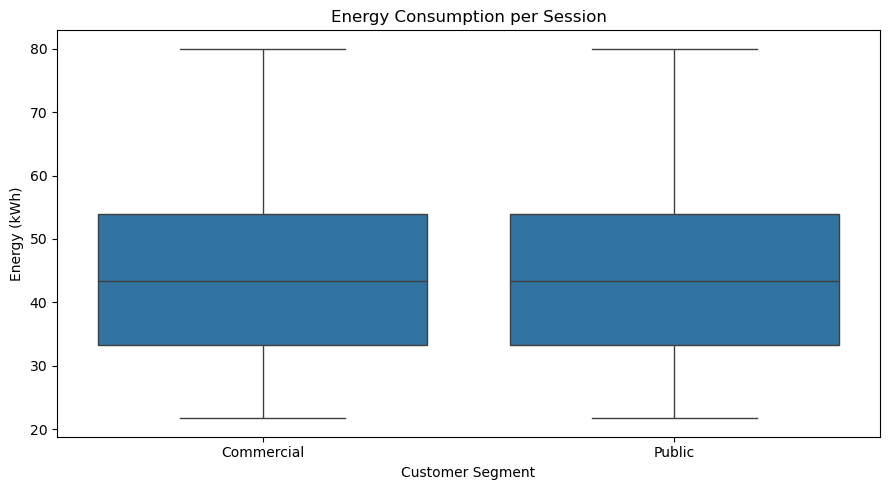

In [35]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=sessions,
    x="customer_segment",
    y="energy_kwh"
)

plt.title("Energy Consumption per Session")
plt.xlabel("Customer Segment")
plt.ylabel("Energy (kWh)")
plt.tight_layout()
plt.show()

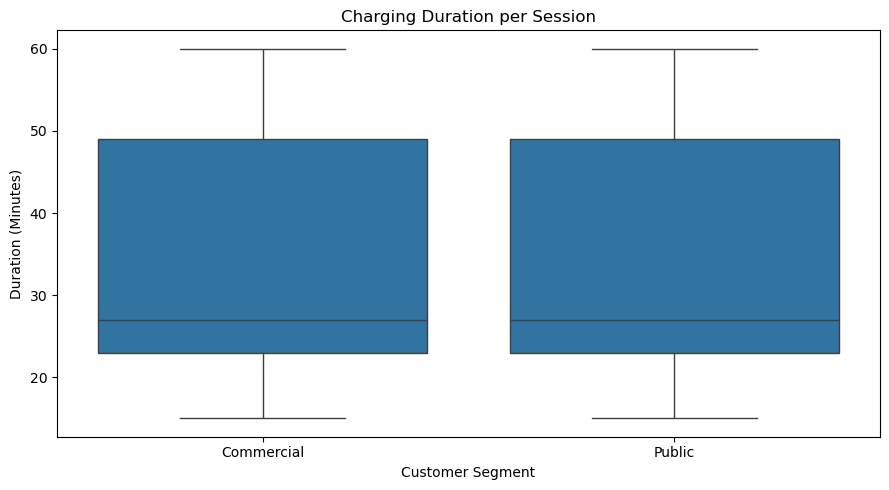

In [36]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=sessions,
    x="customer_segment",
    y="session_duration_minutes"
)

plt.title("Charging Duration per Session")
plt.xlabel("Customer Segment")
plt.ylabel("Duration (Minutes)")
plt.tight_layout()
plt.show()

In [37]:
final_comparison = (
    sessions.groupby("customer_segment")
    .agg(
        total_sessions=("session_id", "count"),
        unique_customer_ids=("customer_id", "nunique"),
        total_energy_kwh=("energy_kwh", "sum"),
        average_energy_per_session=("energy_kwh", "mean"),
        total_revenue=("total_cost", "sum"),
        average_revenue_per_session=("total_cost", "mean"),
        average_session_duration=("session_duration_minutes", "mean")
    )
    .reset_index()
)

final_comparison["sessions_per_customer_id"] = (
    final_comparison["total_sessions"] /
    final_comparison["unique_customer_ids"]
)

final_comparison["energy_per_customer_id"] = (
    final_comparison["total_energy_kwh"] /
    final_comparison["unique_customer_ids"]
)

final_comparison["revenue_per_customer_id"] = (
    final_comparison["total_revenue"] /
    final_comparison["unique_customer_ids"]
)

final_comparison

,customer_segment,total_sessions,unique_customer_ids,total_energy_kwh,average_energy_per_session,total_revenue,average_revenue_per_session,average_session_duration,sessions_per_customer_id,energy_per_customer_id,revenue_per_customer_id
0,Commercial,220270,7510,"10,344,901.20",46.96,"6,120,481.87",27.79,35.10,29.33,"1,377.48",814.98
1,Public,73754,6452,"3,463,844.60",46.96,"2,050,618.25",27.80,35.08,11.43,536.86,317.83


In [38]:
final_comparison["revenue_share_pct"] = (
    final_comparison["total_revenue"] /
    final_comparison["total_revenue"].sum() * 100
)

final_comparison

,customer_segment,total_sessions,unique_customer_ids,total_energy_kwh,average_energy_per_session,total_revenue,average_revenue_per_session,average_session_duration,sessions_per_customer_id,energy_per_customer_id,revenue_per_customer_id,revenue_share_pct
0,Commercial,220270,7510,"10,344,901.20",46.96,"6,120,481.87",27.79,35.10,29.33,"1,377.48",814.98,74.90
1,Public,73754,6452,"3,463,844.60",46.96,"2,050,618.25",27.80,35.08,11.43,536.86,317.83,25.10


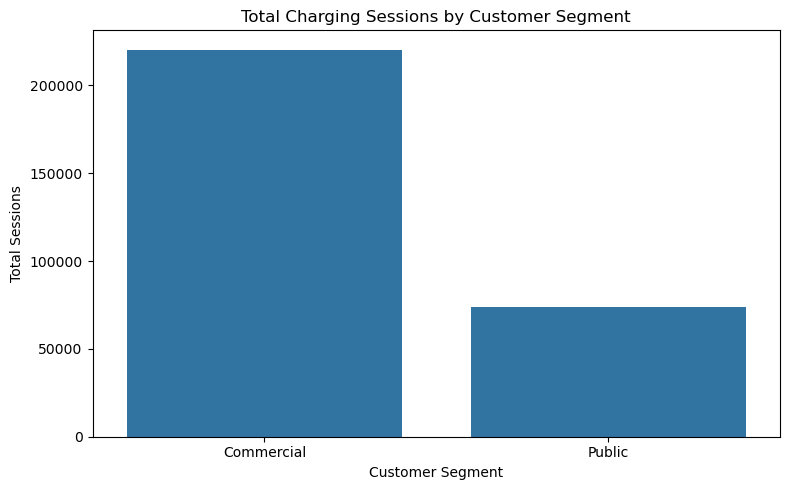

In [39]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=final_comparison,
    x="customer_segment",
    y="total_sessions"
)

plt.title("Total Charging Sessions by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Sessions")
plt.tight_layout()
plt.show()

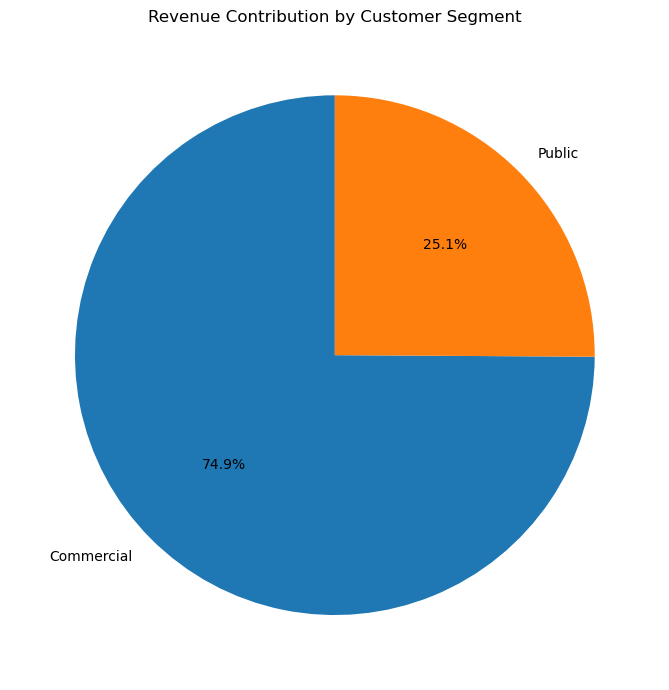

In [40]:
plt.figure(figsize=(7, 7))

plt.pie(
    final_comparison["revenue_share_pct"],
    labels=final_comparison["customer_segment"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Revenue Contribution by Customer Segment")
plt.tight_layout()
plt.show()

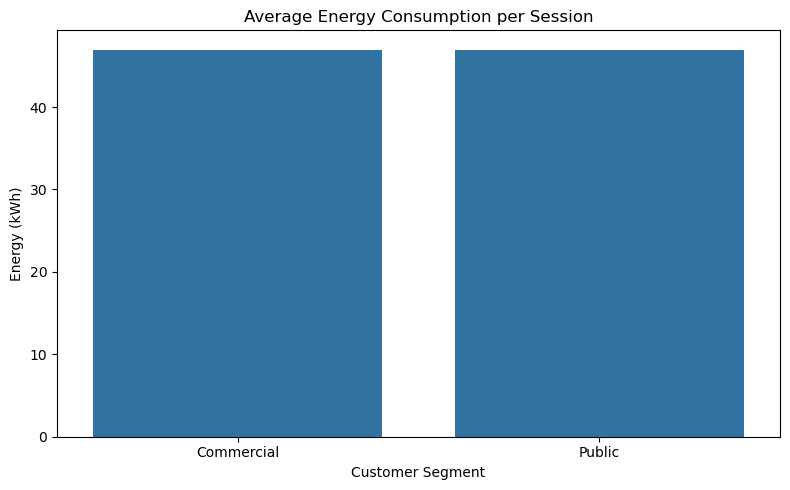

In [41]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=final_comparison,
    x="customer_segment",
    y="average_energy_per_session"
)

plt.title("Average Energy Consumption per Session")
plt.xlabel("Customer Segment")
plt.ylabel("Energy (kWh)")
plt.tight_layout()
plt.show()

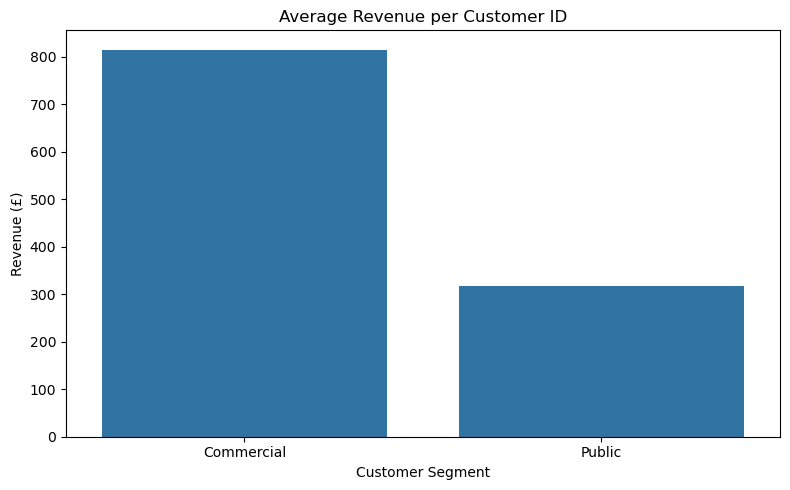

In [42]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=final_comparison,
    x="customer_segment",
    y="revenue_per_customer_id"
)

plt.title("Average Revenue per Customer ID")
plt.xlabel("Customer Segment")
plt.ylabel("Revenue (£)")
plt.tight_layout()
plt.show()

In [43]:
from pathlib import Path

output_path = Path("analysis")
output_path.mkdir(exist_ok=True)

final_comparison.to_csv(output_path / "segment_comparison.csv", index=False)
regional_comparison.to_csv(output_path / "regional_comparison.csv", index=False)
charger_comparison.to_csv(output_path / "charger_comparison.csv", index=False)
payment_comparison.to_csv(output_path / "payment_comparison.csv", index=False)
monthly_comparison.to_csv(output_path / "monthly_comparison.csv", index=False)
annual_comparison.to_csv(output_path / "annual_comparison.csv", index=False)

In [44]:
customer_analysis.to_csv(output_path / "customer_id_analysis.csv", index=False)
user_distribution.to_csv(output_path / "user_type_distribution.csv", index=False)

In [45]:
list(output_path.iterdir())

[WindowsPath('analysis/.gitkeep'),
 WindowsPath('analysis/annual_comparison.csv'),
 WindowsPath('analysis/charger_comparison.csv'),
 WindowsPath('analysis/customer_id_analysis.csv'),
 WindowsPath('analysis/monthly_comparison.csv'),
 WindowsPath('analysis/payment_comparison.csv'),
 WindowsPath('analysis/regional_comparison.csv'),
 WindowsPath('analysis/segment_comparison.csv'),
 WindowsPath('analysis/user_type_distribution.csv')]